<a href="https://colab.research.google.com/github/vcasadei/Redes-Neurais-CESAR-School/blob/2026.01-A/2%20-%20Regress%C3%A3o%20Linear/2.6_regressao_linear_salarios.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir no Colab"/></a>

# Atividade 2 — Regressão Linear Múltipla (California Housing)

Nesta atividade, o objetivo é treinar um modelo de regressão linear múltipla usando PyTorch para prever o preço de casas na Califórnia, usando o dataset `California Housing` do `scikit-learn`.

## Objetivos

- Nesta atividade você vai treinar uma regressão linear com várias variáveis de entrada, em PyTorch, para prever o preço de casas na Califórnia. O dataset California Housing vem no scikit-learn e baixa sem login:

         from sklearn.datasets import fetch_california_housing
         dados = fetch_california_housing(as_frame=True)
         X, y = dados.data, dados.target # 20.640 quarteirões, 8 variáveis; y em centenas de milhares de dólares

Use como ponto de partida o notebook 2.6_regressao_linear_salarios.ipynb. O 2.6 tem uma variável de entrada; aqui são 8, então o modelo passa a ser nn.Linear(8, 1).

O notebook deve conter:
Uma breve análise dos dados: o que cada variável significa, describe() e um gráfico de dispersão de pelo menos duas variáveis contra o preço.
Divisão em treino, validação e teste (por exemplo 70/15/15, com random_state fixo).
Padronização das entradas e da saída com StandardScaler ajustado só no treino.
Treinamento com nn.Linear(8, 1), nn.MSELoss e optim.SGD, com as curvas de custo de treino e de validação.
RMSE no teste em dólares, comparado com um baseline que sempre prevê o preço médio do treino.
Os 8 pesos aprendidos: quais variáveis mais aumentam e quais mais diminuem o preço previsto? Por que só faz sentido comparar os pesos entre si porque as entradas foram padronizadas?
Uma conclusão curta: o modelo é bom o suficiente? O que você tentaria para melhorar?

## Importação das bibliotecas

In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


## Carregando os dados

Resumo estatístico:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000


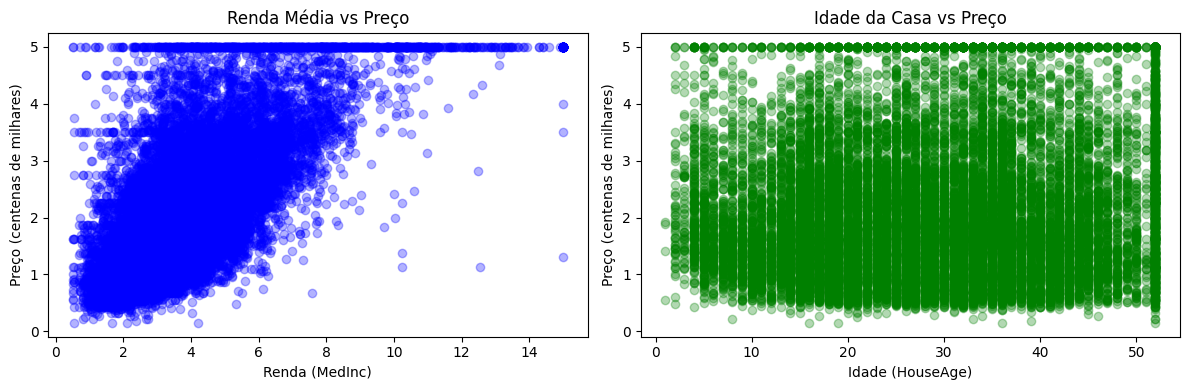

In [33]:

# Carregando os dados
dados = fetch_california_housing(as_frame=True)
X, y = dados.data, dados.target

# O que cada variável significa:
# MedInc: Renda média do quarteirão
# HouseAge: Idade média das casas
# AveRooms: Média de quartos por casa
# AveBedrms: Média de quartos usados como dormitório
# Population: População do quarteirão
# AveOccup: Média de moradores por casa
# Latitude/Longitude: Localização geográfica
# Target (MedHouseVal): Preço médio da casa (em centenas de milhares de dólares)

print("Resumo estatístico:")
display(X.describe())

# Gráfico de dispersão: Renda vs Preço e Idade vs Preço
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].scatter(X['MedInc'], y, alpha=0.3, color='blue')
ax[0].set_title('Renda Média vs Preço')
ax[0].set_xlabel('Renda (MedInc)')
ax[0].set_ylabel('Preço (centenas de milhares)')

ax[1].scatter(X['HouseAge'], y, alpha=0.3, color='green')
ax[1].set_title('Idade da Casa vs Preço')
ax[1].set_xlabel('Idade (HouseAge)')
ax[1].set_ylabel('Preço (centenas de milhares)')

plt.tight_layout()
plt.show()

## Visualização e tratamento

Resumo Estatístico


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010



Valores nulos:


MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

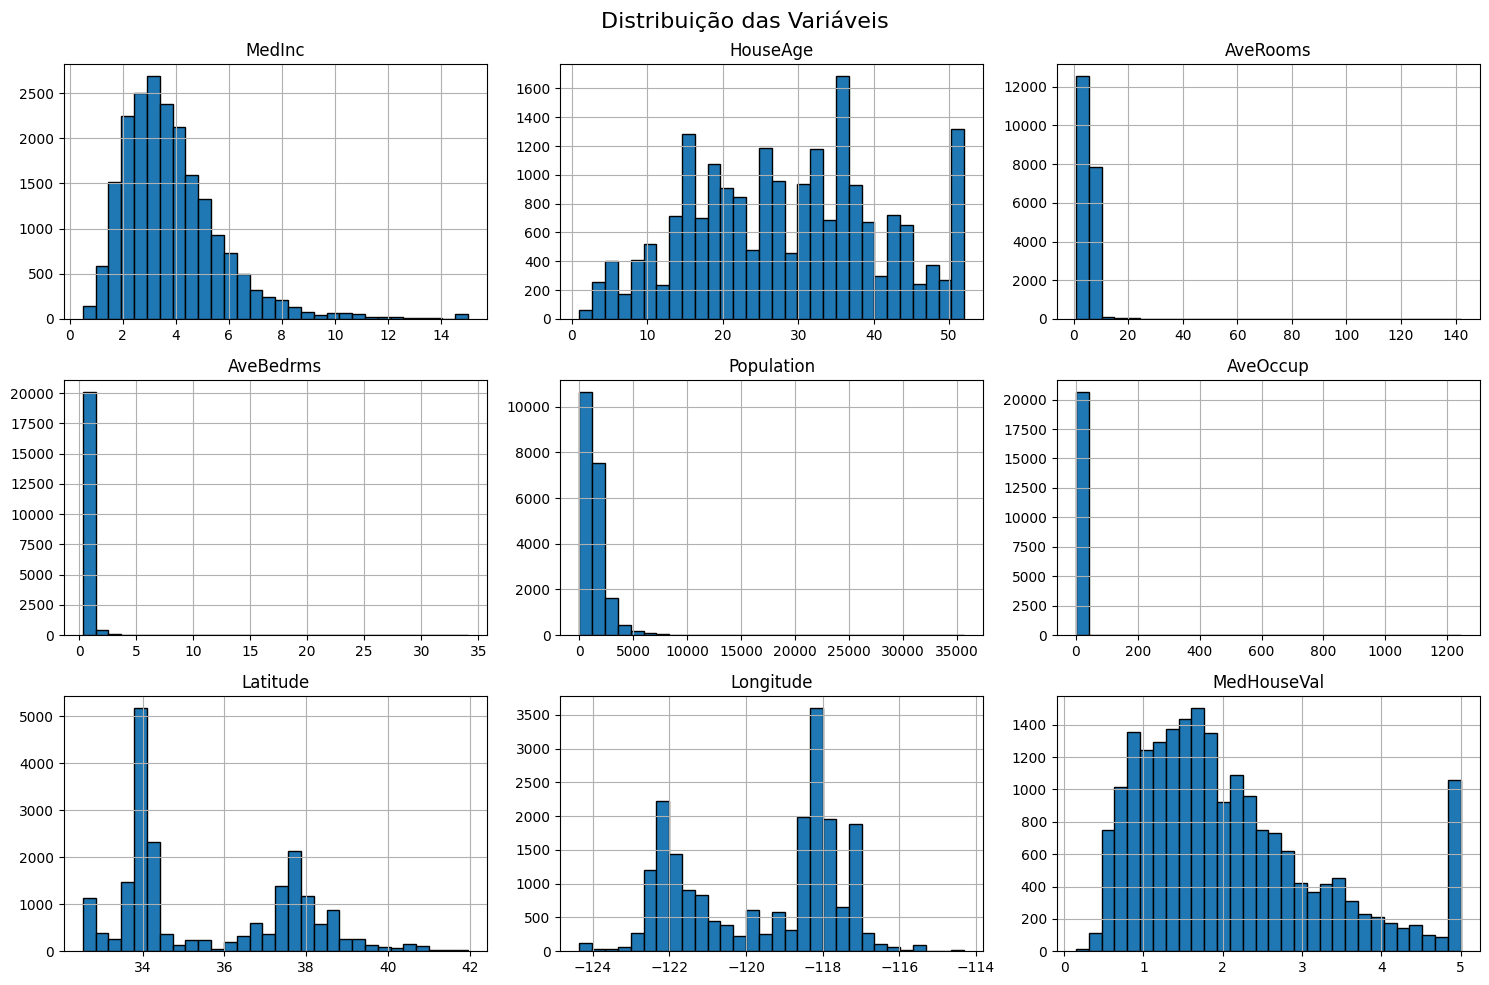

In [ ]:
# Carregando os dados
dados = fetch_california_housing(as_frame=True)

X = dados.data
y = dados.target

# Dataset completo
df = X.copy()
df['MedHouseVal'] = y

# 1. Estatísticas descritivas
print("Resumo Estatístico")
display(df.describe())

# 2. Valores ausentes

print("\nValores nulos:")
display(df.isnull().sum())

# 3. Histogramas
df.hist(
    figsize=(15,10),
    bins=30,
    edgecolor='black'
)

plt.suptitle("Distribuição das Variáveis", fontsize=16)
plt.tight_layout()
plt.show()

## Divisão e Padronização

In [34]:
# 1. Divisão em treino (70%), validação (15%) e teste (15%)
X_train_full, X_test, y_train_full, y_test = train_test_split(X, y, test_size=0.15, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train_full, y_train_full, test_size=0.1765, random_state=42) 

# 2. Padronização (fit APENAS no treino)
x_scaler = StandardScaler().fit(X_train)
y_scaler = StandardScaler().fit(y_train.values.reshape(-1, 1))

X_train_scaled = x_scaler.transform(X_train)
X_val_scaled = x_scaler.transform(X_val)
X_test_scaled = x_scaler.transform(X_test)

y_train_scaled = y_scaler.transform(y_train.values.reshape(-1, 1))
y_val_scaled = y_scaler.transform(y_val.values.reshape(-1, 1))
y_test_scaled = y_scaler.transform(y_test.values.reshape(-1, 1))

# Convertendo para tensores PyTorch
X_train_t = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_t = torch.tensor(y_train_scaled, dtype=torch.float32)
X_val_t = torch.tensor(X_val_scaled, dtype=torch.float32)
y_val_t = torch.tensor(y_val_scaled, dtype=torch.float32)
X_test_t = torch.tensor(X_test_scaled, dtype=torch.float32)
y_test_t = torch.tensor(y_test_scaled, dtype=torch.float32)

## Treinamento e Curvas de Custo

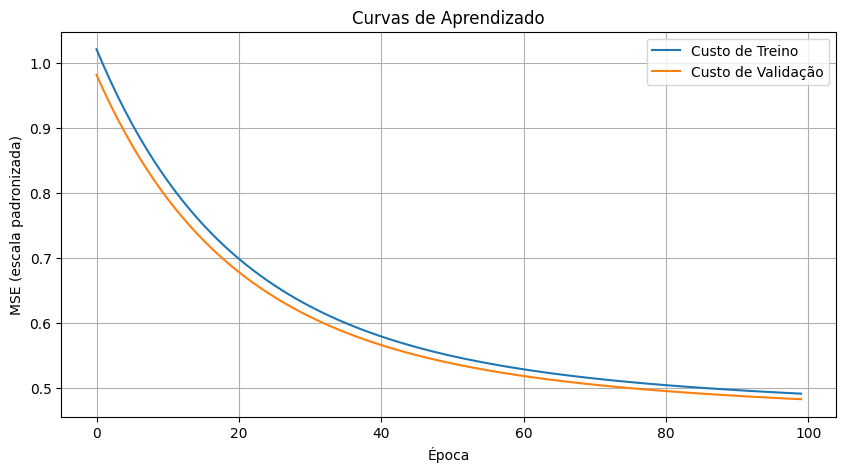

In [35]:
# Criando o modelo com 8 entradas e 1 saída
model = nn.Linear(8, 1)
criterion = nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.01)

n_epochs = 100
train_losses = []
val_losses = []

for epoch in range(n_epochs):
    # Treino
    model.train()
    optimizer.zero_grad()
    y_pred = model(X_train_t)
    loss = criterion(y_pred, y_train_t)
    loss.backward()
    optimizer.step()
    train_losses.append(loss.item())
    
    # Validação
    model.eval()
    with torch.no_grad():
        y_val_pred = model(X_val_t)
        val_loss = criterion(y_val_pred, y_val_t)
        val_losses.append(val_loss.item())

# Plotando as curvas
plt.figure(figsize=(10, 5))
plt.plot(train_losses, label='Custo de Treino')
plt.plot(val_losses, label='Custo de Validação')
plt.xlabel('Época')
plt.ylabel('MSE (escala padronizada)')
plt.title('Curvas de Aprendizado')
plt.legend()
plt.grid(True)
plt.show()

## Avaliação no Teste e Baseline

In [36]:
# 1. Avaliação no teste
model.eval()
with torch.no_grad():
    y_pred_test_scaled = model(X_test_t)
    y_pred_test = y_scaler.inverse_transform(y_pred_test_scaled.numpy())
    y_test_real = y_scaler.inverse_transform(y_test_t.numpy())

# RMSE do modelo (em dólares)
rmse_modelo = np.sqrt(np.mean((y_pred_test - y_test_real) ** 2))

# 2. Baseline: sempre prevê a média do treino
media_treino = y_train.mean()
baseline_preds = np.full_like(y_test_real, media_treino)
rmse_baseline = np.sqrt(np.mean((baseline_preds - y_test_real) ** 2))

print(f"RMSE do Modelo: ${rmse_modelo * 100_000:.2f}")
print(f"RMSE do Baseline: ${rmse_baseline * 100_000:.2f}")

RMSE do Modelo: $80504.74
RMSE do Baseline: $114479.20


## Respostas Teóricas

### Análise dos Pesos
(Execute o código abaixo para ver os pesos)

**Por que só faz sentido comparar os pesos entre si?**
Porque as entradas foram padronizadas (média 0, desvio padrão 1) com o StandardScaler. Sem a padronização, variáveis com números absolutos maiores (como Population) teriam pesos artificialmente menores só para compensar a escala, enquanto as menores teriam pesos maiores. Com a padronização, todos estão na mesma régua, e o peso dita o real impacto da variável.

### Conclusão
O modelo é melhor que o baseline (chutar a média), mas ainda tem um erro considerável. Para melhorar, eu tentaria:
1. Usar um modelo não-linear (Redes Neurais com camadas ocultas).
2. Criar novas features (ex: distância até o mar, renda por habitante).
3. Testar o otimizador Adam em vez do SGD.

## Os 8 Pesos

In [37]:
pesos = model.weight.data.numpy()[0]
variaveis = X.columns

print("Pesos aprendidos:")
for var, peso in zip(variaveis, pesos):
    sinal = "aumenta" if peso > 0 else "diminui"
    print(f"{var}: {peso:.4f} ({sinal} o preço)")

Pesos aprendidos:
MedInc: 0.5434 (aumenta o preço)
HouseAge: 0.1858 (aumenta o preço)
AveRooms: 0.2097 (aumenta o preço)
AveBedrms: -0.1835 (diminui o preço)
Population: 0.0492 (aumenta o preço)
AveOccup: -0.0576 (diminui o preço)
Latitude: -0.1827 (diminui o preço)
Longitude: -0.1393 (diminui o preço)
